# Phase 3 – Bike Demand Prediction Model


## 1. Setup


In [1]:
import os, glob, zipfile, sys
if not (os.path.exists("data/hour.csv") and os.path.exists("data/day.csv")):
    try:
        from google.colab import files
        uploaded = files.upload()
        zip_name = [f for f in uploaded if f.lower().endswith(".zip")][0]
    except ImportError:
        zip_name = glob.glob("*.zip")[0]
    os.makedirs("data", exist_ok=True)
    with zipfile.ZipFile(zip_name) as z:
        for member in z.namelist():
            name = os.path.basename(member)
            if name in ("hour.csv", "day.csv", "Readme.txt"):
                with z.open(member) as src, open(os.path.join("data", name), "wb") as dst:
                    dst.write(src.read())
for d in ["src", "models", "outputs/model_results"]:
    os.makedirs(d, exist_ok=True)
print(sorted(os.listdir("data")))


['day.csv', 'hour.csv']


In [2]:
%%writefile src/preprocessing.py
from __future__ import annotations

import numpy as np
import pandas as pd

TEMP_MAX_C, ATEMP_MAX_C, HUM_MAX, WIND_MAX = 41, 50, 100, 67

DISRUPTED_DAYS = pd.to_datetime([
    "2011-01-18", "2011-01-26", "2011-01-27", "2011-02-22",
    "2011-08-27", "2011-08-28", "2012-10-29", "2012-10-30",
])

CLEANING_LOG = [
    ("hum == 0 on 2011-03-10 (22 hourly rows, 1 daily row)",
     "Physically impossible -> sensor error. Replaced with the mean humidity of the same hour on "
     "the previous and next day (daily file: mean of neighbouring days). Flag column `hum_imputed`."),
    ("weathersit == 4 (3 hourly rows)",
     "Too rare to learn from. New column `weather` merges 4 into 3 ('rain/snow'). Raw column kept."),
    ("windspeed == 0 (12.5% of hours; next value is 0.0896)",
     "Likely 'calm / not recorded'. Kept unchanged, flagged in `wind_zero`. Low impact on demand."),
    ("165 missing hours (mostly 02:00-05:00; storm shutdowns)",
     "Not filled with invented rows for EDA/model training. Zero-rental hours appear to be absent, "
     "so night-time averages are slightly overstated. Storm days flagged in `disrupted_day`."),
    ("High cnt values (up to 977/hr)",
     "Genuine commute peaks (Phase 1, Step 10). Not removed."),
]


def load_hour(path: str = "data/hour.csv") -> pd.DataFrame:
    return pd.read_csv(path, parse_dates=["dteday"])


def load_day(path: str = "data/day.csv") -> pd.DataFrame:
    return pd.read_csv(path, parse_dates=["dteday"])


def _impute_hourly_humidity(df: pd.DataFrame) -> pd.DataFrame:
    bad = df["hum"] == 0
    df["hum_imputed"] = bad.astype(int)
    if not bad.any():
        return df
    lookup = df.loc[~bad].set_index(["dteday", "hr"])["hum"]
    for idx in df.index[bad]:
        d, h = df.at[idx, "dteday"], df.at[idx, "hr"]
        neighbours = [lookup.get((d + pd.Timedelta(days=k), h)) for k in (-1, 1)]
        neighbours = [v for v in neighbours if v is not None and not pd.isna(v)]
        df.at[idx, "hum"] = np.mean(neighbours) if neighbours else df.loc[~bad, "hum"].median()
    return df


def clean_hour(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.copy().sort_values(["dteday", "hr"]).reset_index(drop=True)
    df["timestamp"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")
    df = _impute_hourly_humidity(df)
    df["weather"] = df["weathersit"].clip(upper=3)
    df["wind_zero"] = (df["windspeed"] == 0).astype(int)
    df["disrupted_day"] = df["dteday"].isin(DISRUPTED_DAYS).astype(int)
    return add_physical_units(df)


def clean_day(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.copy().sort_values("dteday").reset_index(drop=True)
    bad = df["hum"] == 0
    df["hum_imputed"] = bad.astype(int)
    for idx in df.index[bad]:
        neigh = df.loc[[i for i in (idx - 1, idx + 1) if i in df.index and not bad[i]], "hum"]
        df.at[idx, "hum"] = neigh.mean()
    df["weather"] = df["weathersit"].clip(upper=3)
    df["disrupted_day"] = df["dteday"].isin(DISRUPTED_DAYS).astype(int)
    return add_physical_units(df)


def add_physical_units(df: pd.DataFrame) -> pd.DataFrame:
    df["temp_c"] = df["temp"] * TEMP_MAX_C
    df["atemp_c"] = df["atemp"] * ATEMP_MAX_C
    df["hum_pct"] = df["hum"] * HUM_MAX
    df["wind_unscaled"] = df["windspeed"] * WIND_MAX
    return df


Writing src/preprocessing.py


In [3]:
%%writefile src/feature_engineering.py
from __future__ import annotations

import numpy as np
import pandas as pd

MORNING_PEAK = (7, 8, 9)
EVENING_PEAK = (16, 17, 18, 19)
PEAK_HOURS = MORNING_PEAK + EVENING_PEAK
NIGHT_HOURS = (0, 1, 2, 3, 4, 5)

FEATURE_RATIONALE = {
    "hr":            "Hour of day - the single strongest driver (commute vs night).",
    "weekday":       "Day of week (0=Sun). Captures Fri/Mon effects beyond the working-day flag.",
    "workingday":    "Commuting happens on working days; changes the whole daily shape.",
    "holiday":       "Public holidays behave like weekends even on Mon-Fri.",
    "is_weekend":    "Sat/Sun indicator - leisure pattern (midday peak).",
    "mnth":          "Month - seasonal temperature/daylight cycle.",
    "season":        "Coarser seasonal signal from the source data.",
    "yr":            "Growth of the system (2012 ~ +63%). Lets the model learn the level shift.",
    "morning_peak":  "Working day AND 07-09 - morning commute window.",
    "evening_peak":  "Working day AND 16-19 - evening commute window.",
    "rush_hour":     "Either commute window on a working day - where shortages are most likely.",
    "night":         "00-05 - near-zero demand; useful window for rebalancing trucks.",
    "hr_sin/hr_cos": "Cyclical hour: tells linear models that 23:00 is next to 00:00.",
    "mnth_sin/mnth_cos": "Cyclical month: December is next to January.",
    "weather":       "1 clear, 2 mist/cloud, 3 rain/snow (4 merged into 3 - only 3 rows).",
    "temp":          "Temperature (normalised). Riding is weather-sensitive.",
    "temp_sq":       "Lets a linear model capture 'too hot' - demand flattens/falls at high temps.",
    "hum":           "Humidity - proxy for discomfort and rain.",
    "windspeed":     "Wind - discomfort on a bike.",
}

EXCLUDED_COLUMNS = {
    "casual":      "Leakage: casual + registered = cnt exactly. Unknown before the hour ends.",
    "registered":  "Leakage: same reason as casual.",
    "cnt":         "Target.",
    "instant":     "Row index; it is a disguised time trend with no causal meaning. `yr` covers the trend explicitly.",
    "dteday":      "Raw date string; decomposed into yr/mnth/weekday instead.",
    "timestamp":   "Helper for sorting/splitting, not a feature.",
    "atemp":       "'Feels-like' temperature, correlation with temp ~0.99 -> redundant; kept out to avoid collinearity.",
    "weathersit":  "Replaced by `weather` (category 4 merged into 3).",
    "hum_imputed / wind_zero / disrupted_day": "Data-quality flags for analysis, not demand drivers.",
    "temp_c / atemp_c / hum_pct / wind_unscaled": "Same information as the scaled columns, used only for readable charts/app.",
}

MODEL_FEATURES = [
    "hr", "weekday", "workingday", "holiday", "is_weekend", "mnth", "season", "yr",
    "morning_peak", "evening_peak", "rush_hour", "night",
    "hr_sin", "hr_cos", "mnth_sin", "mnth_cos",
    "weather", "temp", "temp_sq", "hum", "windspeed",
]


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["is_weekend"] = out["weekday"].isin([0, 6]).astype(int)
    if "hr" in out:
        hr = out["hr"]
        out["morning_peak"] = (hr.isin(MORNING_PEAK) & (out["workingday"] == 1)).astype(int)
        out["evening_peak"] = (hr.isin(EVENING_PEAK) & (out["workingday"] == 1)).astype(int)
        out["rush_hour"] = (out["morning_peak"] | out["evening_peak"]).astype(int)
        out["night"] = hr.isin(NIGHT_HOURS).astype(int)
        out["hr_sin"] = np.sin(2 * np.pi * hr / 24)
        out["hr_cos"] = np.cos(2 * np.pi * hr / 24)
    out["mnth_sin"] = np.sin(2 * np.pi * (out["mnth"] - 1) / 12)
    out["mnth_cos"] = np.cos(2 * np.pi * (out["mnth"] - 1) / 12)
    out["temp_sq"] = out["temp"] ** 2
    out["day_type"] = np.where(out["workingday"] == 1, "Working day", "Non-working day")
    return out


def daily_peak_share(hour_df: pd.DataFrame, min_hours: int = 22) -> pd.DataFrame:
    g = hour_df.assign(in_peak=hour_df["hr"].isin(PEAK_HOURS) * hour_df["cnt"])
    daily = g.groupby("dteday").agg(
        cnt=("cnt", "sum"), peak_cnt=("in_peak", "sum"), n_hours=("hr", "size"),
        workingday=("workingday", "first"), yr=("yr", "first"), season=("season", "first"),
        mnth=("mnth", "first"), weather_mean=("weather", "mean"), temp=("temp", "mean"),
        hum=("hum", "mean"), windspeed=("windspeed", "mean"),
    ).reset_index()
    daily = daily[daily["n_hours"] >= min_hours].copy()
    daily["peak_share"] = daily["peak_cnt"] / daily["cnt"]
    return daily


Writing src/feature_engineering.py


In [4]:
%%writefile src/model_training.py
from __future__ import annotations

import time

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

import feature_engineering as fe

SEED = 42
TRAIN_END = pd.Timestamp("2012-06-30")
TEST_START = pd.Timestamp("2012-07-01")
CV_MONTHS = ["2012-03", "2012-04", "2012-05", "2012-06"]
LAG_FEATURES = ["lag_168", "same_hour_4wk_mean"]


def chrono_split(df: pd.DataFrame):
    train = df[df["dteday"] <= TRAIN_END].copy()
    test = df[df["dteday"] >= TEST_START].copy()
    return train, test


def time_folds(train: pd.DataFrame):
    for m in CV_MONTHS:
        start = pd.Timestamp(m + "-01")
        end = start + pd.offsets.MonthEnd(0)
        tr = train.index[train["dteday"] < start]
        va = train.index[(train["dteday"] >= start) & (train["dteday"] <= end)]
        yield m, tr, va


class HourProfileBaseline(BaseEstimator, RegressorMixin):

    def fit(self, X, y):
        d = pd.DataFrame({"hr": X["hr"].values, "wd": X["workingday"].values, "y": np.asarray(y)})
        self.table_ = d.groupby(["hr", "wd"]).y.mean()
        self.global_ = float(np.mean(y))
        return self

    def predict(self, X):
        keys = list(zip(X["hr"].values, X["workingday"].values))
        return np.array([self.table_.get(k, self.global_) for k in keys])


def add_hour_daytype(X: pd.DataFrame) -> pd.DataFrame:
    X = X.copy()
    X["hr_wd"] = X["hr"].astype(int) * 10 + X["workingday"].astype(int)
    return X


LINEAR_CATEGORICAL = ["hr_wd", "weather", "mnth"]
LINEAR_NUMERIC = ["yr", "holiday", "temp", "temp_sq", "hum", "windspeed"]


def linear_pipeline() -> Pipeline:
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), LINEAR_CATEGORICAL),
        ("num", StandardScaler(), LINEAR_NUMERIC),
    ])
    return Pipeline([("hour_x_daytype", FunctionTransformer(add_hour_daytype)), ("prep", pre),
                     ("model", LinearRegression())])


def log_target(model):
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)


def candidate_models() -> dict:
    rf = lambda leaf: RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, max_features=0.5,
                                            n_jobs=-1, random_state=SEED)
    gb = lambda depth: GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=depth,
                                                 subsample=0.8, random_state=SEED)
    return {
        "Dummy (training mean)": DummyRegressor(strategy="mean"),
        "Baseline: hour x day-type average": HourProfileBaseline(),
        "Linear regression": linear_pipeline(),
        "Linear regression (log target)": log_target(linear_pipeline()),
        "Decision tree (depth 10)": DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=SEED),
        "Decision tree (depth 14)": DecisionTreeRegressor(max_depth=14, min_samples_leaf=5, random_state=SEED),
        "Random forest (leaf 1)": rf(1),
        "Random forest (leaf 3)": rf(3),
        "Random forest (leaf 3, log target)": log_target(rf(3)),
        "Gradient boosting (depth 4)": gb(4),
        "Gradient boosting (depth 6)": gb(6),
        "Gradient boosting (depth 6, log target)": log_target(gb(6)),
    }


def evaluate(y_true, y_pred, is_peak=None) -> dict:
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_pred - y_true
    out = {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "WAPE_%": 100 * np.abs(err).sum() / y_true.sum(),
        "Bias (mean pred - actual)": err.mean(),
    }
    if is_peak is not None:
        p = np.asarray(is_peak, bool)
        out["Peak MAE"] = np.abs(err[p]).mean()
        out["Peak bias"] = err[p].mean()
        out["Peak under-predicted %"] = 100 * (err[p] < 0).mean()
    return out


def cross_validate(models: dict, train: pd.DataFrame, features: list, target: str = "cnt") -> pd.DataFrame:
    rows = []
    for name, est in models.items():
        t0 = time.time()
        for fold, tr, va in time_folds(train):
            m = clone(est).fit(train.loc[tr, features], train.loc[tr, target])
            pred = np.clip(m.predict(train.loc[va, features]), 0, None)
            rows.append({"model": name, "fold": fold, **evaluate(train.loc[va, target], pred, train.loc[va, "rush_hour"])})
        rows[-1]["fit_seconds"] = time.time() - t0
    res = pd.DataFrame(rows)
    summary = res.groupby("model", sort=False).mean(numeric_only=True)
    return summary.sort_values("MAE"), res


def add_lag_features(df: pd.DataFrame) -> pd.DataFrame:
    s = df.set_index("timestamp")["cnt"]
    full = pd.date_range(s.index.min(), s.index.max(), freq="h")
    s = s.reindex(full).fillna(0)
    lags = pd.concat({k: s.shift(168 * k) for k in (1, 2, 3, 4)}, axis=1)
    feats = pd.DataFrame({"lag_168": lags[1], "same_hour_4wk_mean": lags.mean(axis=1, skipna=False)})
    out = df.join(feats, on="timestamp")
    return out


def quantile_models(alpha_low=0.1, alpha_high=0.9) -> dict:
    q = lambda a: GradientBoostingRegressor(loss="quantile", alpha=a, n_estimators=400, learning_rate=0.05,
                                            max_depth=6, subsample=0.8, random_state=SEED)
    return {f"P{int(alpha_low * 100)}": q(alpha_low), f"P{int(alpha_high * 100)}": q(alpha_high)}


def out_of_fold_predictions(est, train: pd.DataFrame, features: list, target: str = "cnt") -> pd.Series:
    preds = []
    for _, tr, va in time_folds(train):
        m = clone(est).fit(train.loc[tr, features], train.loc[tr, target])
        preds.append(pd.Series(np.clip(m.predict(train.loc[va, features]), 0, None), index=va))
    return pd.concat(preds)


def planning_multipliers(actual: pd.Series, predicted: pd.Series, is_rush: pd.Series, q: float = 0.9) -> dict:
    ratio = (np.asarray(actual) + 1) / (np.asarray(predicted) + 1)
    grp = np.where(np.asarray(is_rush) == 1, "rush", "other")
    return pd.Series(ratio, index=grp).groupby(level=0).quantile(q).to_dict()


def planning_forecast(point: np.ndarray, is_rush, multipliers: dict) -> np.ndarray:
    f = np.where(np.asarray(is_rush) == 1, multipliers["rush"], multipliers["other"])
    return np.clip((np.asarray(point) + 1) * f - 1, 0, None)


def walk_forward(est, df: pd.DataFrame, features: list, months: list, target: str = "cnt") -> pd.Series:
    preds = []
    for m in months:
        start = pd.Timestamp(m + "-01")
        end = start + pd.offsets.MonthEnd(0)
        a = df[df["dteday"] < start]
        b = df[(df["dteday"] >= start) & (df["dteday"] <= end)]
        mm = clone(est).fit(a[features], a[target])
        preds.append(pd.Series(np.clip(mm.predict(b[features]), 0, None), index=b.index))
    return pd.concat(preds)


def bikes_in_use(rentals_per_hour, trip_minutes: float):
    return rentals_per_hour * trip_minutes / 60


def save_bundle(path: str, **items):
    import joblib, sklearn
    items["sklearn_version"] = sklearn.__version__
    joblib.dump(items, path)


def load_bundle(path: str) -> dict:
    import joblib
    return joblib.load(path)


def season_for(date) -> int:
    md = (pd.Timestamp(date).month, pd.Timestamp(date).day)
    if md >= (12, 21) or md < (3, 21):
        return 1
    if md < (6, 21):
        return 2
    if md < (9, 23):
        return 3
    return 4


def scenario_frame(date, hours=range(24), weather: int = 1, temp_c: float | None = None,
                   hum_pct: float | None = None, wind: float | None = None, holiday: int = 0,
                   climate: pd.DataFrame | None = None, yr: int = 1) -> pd.DataFrame:
    date = pd.Timestamp(date)
    rows = []
    for h in hours:
        clim = climate.loc[(date.month, h)] if climate is not None else None
        t = temp_c if temp_c is not None else clim["temp_c"]
        hu = hum_pct if hum_pct is not None else clim["hum_pct"]
        w = wind if wind is not None else clim["wind_unscaled"]
        weekday = (date.dayofweek + 1) % 7
        workingday = int(weekday in (1, 2, 3, 4, 5) and not holiday)
        rows.append({"dteday": date.normalize(), "hr": h, "weekday": weekday, "workingday": workingday,
                     "holiday": int(holiday), "mnth": date.month, "season": season_for(date), "yr": min(int(yr), 1),
                     "weather": int(weather), "temp": t / 41, "hum": hu / 100, "windspeed": w / 67})
    return fe.add_features(pd.DataFrame(rows))


def climate_table(hour_df: pd.DataFrame) -> pd.DataFrame:
    return hour_df.groupby(["mnth", "hr"])[["temp_c", "hum_pct", "wind_unscaled"]].median()


Writing src/model_training.py


In [5]:
import importlib, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

sys.path.insert(0, "src")
import preprocessing as pp, feature_engineering as fe, model_training as mt
for m in (pp, fe, mt):
    importlib.reload(m)
warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
np.random.seed(mt.SEED)

BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK2, GRID, SURFACE = "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#b9b8b0", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False,
})


## 2. Train / test split and leakage check


In [6]:
hour = fe.add_features(pp.clean_hour(pp.load_hour("data/hour.csv")))
F = fe.MODEL_FEATURES
assert not set(F) & {"casual", "registered", "cnt", "instant", "atemp"}, "leakage!"

train, test = mt.chrono_split(hour)
print(f"Train: {train.dteday.min().date()} -> {train.dteday.max().date()}  ({len(train):,} hours)")
print(f"Test : {test.dteday.min().date()} -> {test.dteday.max().date()}  ({len(test):,} hours)  <- used ONCE, for the chosen model")
print("Validation folds (expanding window inside train):", mt.CV_MONTHS)
print(f"\nAverage cnt  train: {train.cnt.mean():.1f} | test: {test.cnt.mean():.1f}")
print(f"Jul-Dec 2011 avg: {hour[(hour.yr == 0) & (hour.mnth >= 7)].cnt.mean():.1f} | Jan-Jun 2012 avg: {train[train.yr == 1].cnt.mean():.1f}")


Train: 2011-01-01 -> 2012-06-30  (13,003 hours)
Test : 2012-07-01 -> 2012-12-31  (4,376 hours)  <- used ONCE, for the chosen model
Validation folds (expanding window inside train): ['2012-03', '2012-04', '2012-05', '2012-06']

Average cnt  train: 167.7 | test: 254.1
Jul-Dec 2011 avg: 163.5 | Jan-Jun 2012 avg: 215.2


## 3. Model comparison (time-ordered cross-validation)


CV finished in 86s


,MAE,RMSE,R2,WAPE_%,Bias (mean pred - actual),Peak MAE,Peak bias,Peak under-predicted %
model,,,,,,,,
"Gradient boosting (depth 6, log target)",42.58,66.58,0.88,17.42,-16.00,76.55,-34.34,63.26
Gradient boosting (depth 6),44.57,67.82,0.89,18.03,-6.36,75.50,-21.11,60.31
Gradient boosting (depth 4),47.35,69.41,0.88,19.14,-9.16,75.41,-32.57,64.30
Random forest (leaf 1),50.36,76.32,0.85,20.52,-27.86,93.85,-57.12,75.92
Random forest (leaf 3),50.92,76.82,0.85,20.77,-29.66,95.39,-60.03,77.24
"Random forest (leaf 3, log target)",56.16,82.72,0.82,22.99,-43.98,107.24,-85.33,83.50
Decision tree (depth 14),57.86,88.96,0.81,23.37,-23.13,92.40,-30.04,67.07
Decision tree (depth 10),60.10,94.57,0.79,24.20,-30.95,93.44,-32.54,68.46
Linear regression (log target),66.09,99.68,0.77,25.97,33.55,139.11,90.32,26.52


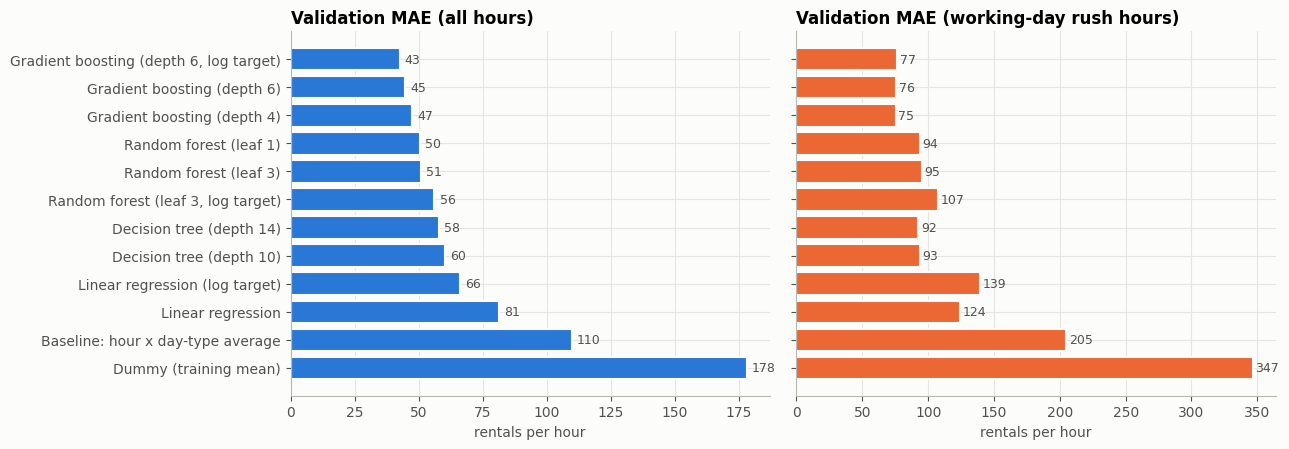

In [7]:
t0 = time.time()
cv_summary, cv_folds = mt.cross_validate(mt.candidate_models(), train, F)
print(f"CV finished in {time.time() - t0:.0f}s")
display(cv_summary.drop(columns="fit_seconds").round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
order = cv_summary.index[::-1]
ax[0].barh(order, cv_summary.loc[order, "MAE"], color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax[0].set(title="Validation MAE (all hours)", xlabel="rentals per hour")
ax[1].barh(order, cv_summary.loc[order, "Peak MAE"], color=ORANGE, edgecolor=SURFACE, linewidth=1.5)
ax[1].set(title="Validation MAE (working-day rush hours)", xlabel="rentals per hour")
for a, col in zip(ax, ["MAE", "Peak MAE"]):
    for y, v in enumerate(cv_summary.loc[order, col]):
        a.text(v + 2, y, f"{v:.0f}", va="center", fontsize=9, color=INK2)
plt.tight_layout(); plt.show()


## 4. Lag features test


In [8]:
hour_lag = mt.add_lag_features(hour)
train_lag, test_lag = mt.chrono_split(hour_lag)
train_lag = train_lag.dropna(subset=mt.LAG_FEATURES)
best = mt.candidate_models()["Gradient boosting (depth 6)"]
s_no, _ = mt.cross_validate({"GB depth 6 – no lags": best}, train_lag, F)
s_lag, _ = mt.cross_validate({"GB depth 6 – with lags": best}, train_lag, F + mt.LAG_FEATURES)
lag_cmp = pd.concat([s_no, s_lag]).drop(columns="fit_seconds")
display(lag_cmp.round(2))


,MAE,RMSE,R2,WAPE_%,Bias (mean pred - actual),Peak MAE,Peak bias,Peak under-predicted %
model,,,,,,,,
GB depth 6 – no lags,43.94,66.15,0.89,17.82,-6.92,72.23,-19.57,58.70
GB depth 6 – with lags,43.57,68.32,0.89,17.60,-6.84,75.57,-28.19,61.07


## 5. Final evaluation on the test set (Jul–Dec 2012)


In [9]:
final_name = "Gradient boosting (depth 6)"
models = mt.candidate_models()
show = ["Dummy (training mean)", "Baseline: hour x day-type average", "Linear regression (log target)",
        "Decision tree (depth 14)", "Random forest (leaf 1)", final_name]
test_rows, fitted = [], {}
for name in show:
    m = clone(models[name]).fit(train[F], train.cnt)
    fitted[name] = m
    p = np.clip(m.predict(test[F]), 0, None)
    test_rows.append({"model": name, **mt.evaluate(test.cnt, p, test.rush_hour)})
test_table = pd.DataFrame(test_rows).set_index("model")
test_table.to_csv("outputs/model_results/test_metrics.csv")
display(test_table.round(2))

final_model = fitted[final_name]
test = test.assign(pred=np.clip(final_model.predict(test[F]), 0, None))
test["resid"] = test.pred - test.cnt


,MAE,RMSE,R2,WAPE_%,Bias (mean pred - actual),Peak MAE,Peak bias,Peak under-predicted %
model,,,,,,,,
Dummy (training mean),177.39,236.06,-0.15,69.81,-86.38,362.26,-354.91,95.03
Baseline: hour x day-type average,107.21,150.35,0.53,42.19,-87.26,218.63,-188.01,91.21
Linear regression (log target),48.87,78.21,0.87,19.23,12.91,92.31,33.39,42.08
Decision tree (depth 14),52.49,80.79,0.86,20.66,-23.97,100.12,-62.86,80.00
Random forest (leaf 1),49.67,74.51,0.88,19.55,-29.50,102.85,-71.39,85.43
Gradient boosting (depth 6),42.74,65.90,0.91,16.82,-21.13,81.23,-49.87,81.27


### 5.1 Actual vs predicted


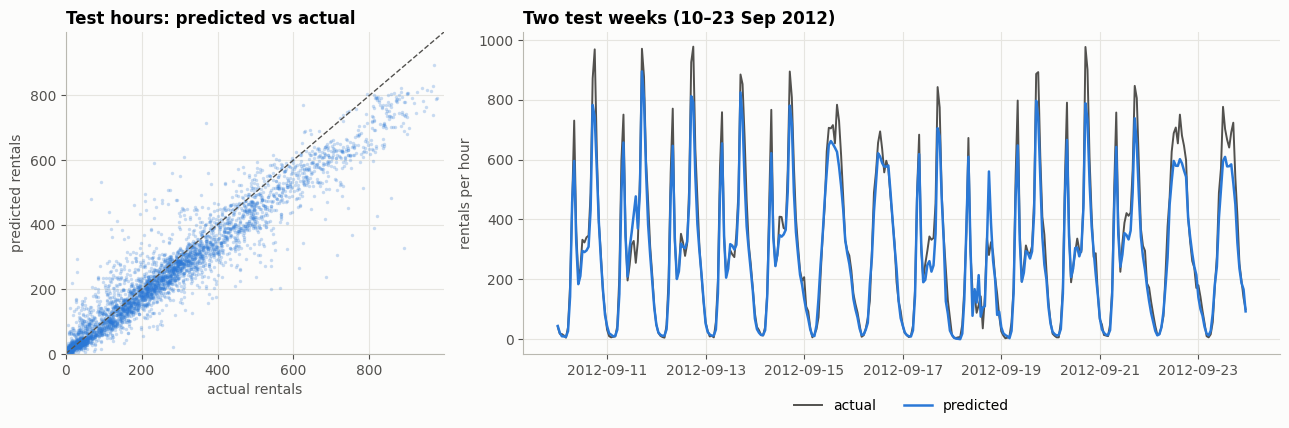

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 2]})
ax[0].scatter(test.cnt, test.pred, s=6, alpha=.25, color=BLUE, linewidths=0)
lim = max(test.cnt.max(), test.pred.max()) * 1.02
ax[0].plot([0, lim], [0, lim], color=INK2, lw=1, ls="--"); ax[0].set(xlim=(0, lim), ylim=(0, lim))
ax[0].set(title="Test hours: predicted vs actual", xlabel="actual rentals", ylabel="predicted rentals")
wk = test[(test.dteday >= "2012-09-10") & (test.dteday <= "2012-09-23")]
ax[1].plot(wk.timestamp, wk.cnt, color=INK2, lw=1.4, label="actual")
ax[1].plot(wk.timestamp, wk.pred, color=BLUE, lw=1.8, label="predicted")
ax[1].set(title="Two test weeks (10–23 Sep 2012)", ylabel="rentals per hour"); ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout(); plt.show()


### 5.2 Residual analysis


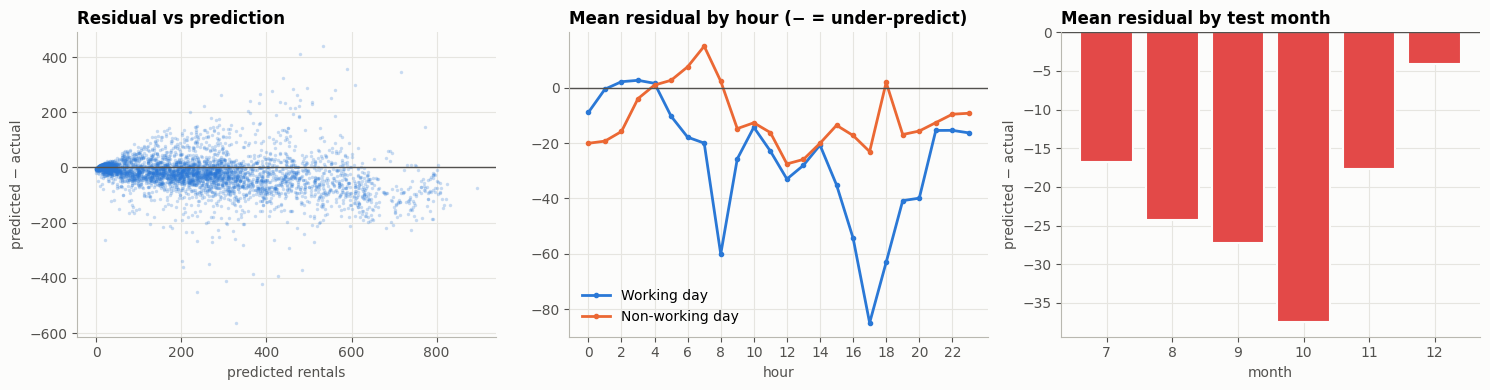

Mean residual by month: {7: -16.7, 8: -24.2, 9: -27.3, 10: -37.5, 11: -17.7, 12: -4.1}
Mean residual at working-day 08:00 / 17:00 / 18:00: {8: -60.1, 17: -84.9, 18: -63.0}
Hurricane Sandy days: actual 1118, predicted 1721 (model has no storm information)


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(test.pred, test.resid, s=6, alpha=.25, color=BLUE, linewidths=0); ax[0].axhline(0, color=INK2, lw=1)
ax[0].set(title="Residual vs prediction", xlabel="predicted rentals", ylabel="predicted − actual")
byhr = test.groupby(["day_type", "hr"]).resid.mean().unstack(0)
ax[1].plot(byhr.index, byhr["Working day"], color=BLUE, marker="o", markersize=3, label="Working day")
ax[1].plot(byhr.index, byhr["Non-working day"], color=ORANGE, marker="o", markersize=3, label="Non-working day")
ax[1].axhline(0, color=INK2, lw=1); ax[1].set(title="Mean residual by hour (− = under-predict)", xlabel="hour", xticks=range(0, 24, 2)); ax[1].legend()
bym = test.groupby("mnth").resid.mean()
ax[2].bar(bym.index, bym.values, color=[RED if v < 0 else BLUE for v in bym.values], edgecolor=SURFACE, linewidth=1.5)
ax[2].axhline(0, color=INK2, lw=1); ax[2].set(title="Mean residual by test month", xlabel="month", ylabel="predicted − actual")
plt.tight_layout(); plt.show()

print("Mean residual by month:", bym.round(1).to_dict())
print("Mean residual at working-day 08:00 / 17:00 / 18:00:", byhr.loc[[8, 17, 18], "Working day"].round(1).to_dict())
sandy = test[test.dteday.isin(pd.to_datetime(["2012-10-29", "2012-10-30"]))]
print(f"Hurricane Sandy days: actual {sandy.cnt.sum()}, predicted {sandy.pred.sum():.0f} (model has no storm information)")


### 5.3 Peak-hour error


In [12]:
test["hour_group"] = np.select(
    [test.rush_hour == 1, test.night == 1, test.workingday == 1],
    ["1 Working-day rush (07-09, 16-19)", "4 Night (00-05)", "2 Working-day other hours"],
    default="3 Non-working day (06-23)")
g = test.assign(abs_err=test.resid.abs(), under=100 * (test.resid < 0))
peak_tbl = g.groupby("hour_group").agg(hours=("cnt", "size"), avg_actual=("cnt", "mean"), MAE=("abs_err", "mean"),
                                       bias=("resid", "mean"), pct_hours_under_predicted=("under", "mean"))
peak_tbl.insert(3, "MAE_as_%_of_actual", 100 * peak_tbl.MAE / peak_tbl.avg_actual)
display(peak_tbl.round(1))
top = test.nlargest(int(len(test) * .05), "cnt")
print(f"Busiest 5% of test hours (cnt >= {top.cnt.min()}): MAE {top.resid.abs().mean():.0f}, bias {top.resid.mean():.0f}, "
      f"under-predicted {100 * (top.resid < 0).mean():.0f}%")


,hours,avg_actual,MAE,MAE_as_%_of_actual,bias,pct_hours_under_predicted
hour_group,,,,,,
"1 Working-day rush (07-09, 16-19)",865,522.6,81.2,15.5,-49.9,81.3
2 Working-day other hours,1360,230.6,35.6,15.4,-23.6,76.2
3 Non-working day (06-23),1062,291.4,53.6,18.4,-11.6,55.6
4 Night (00-05),1089,33.8,10.5,31.0,-4.6,52.8


Busiest 5% of test hours (cnt >= 704): MAE 125, bias -125, under-predicted 98%


### 5.4 Feature importance


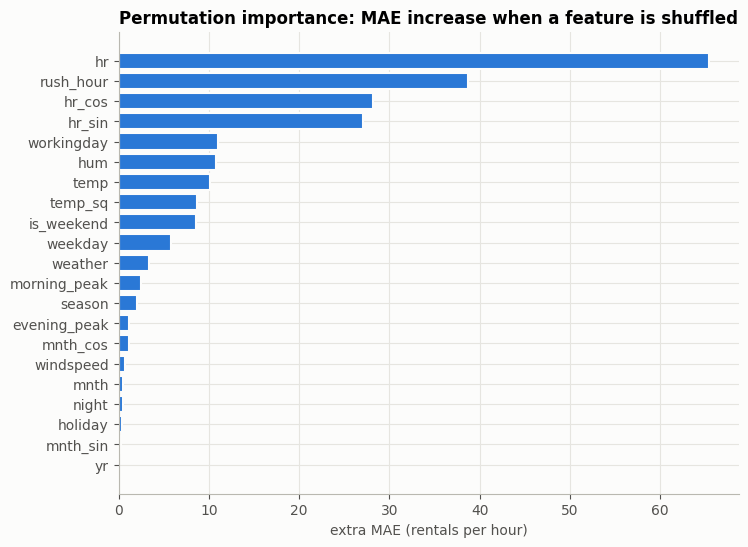

hr            65.4
rush_hour     38.7
hr_cos        28.1
hr_sin        27.1
workingday    11.1
hum           10.7
temp          10.1
temp_sq        8.6
is_weekend     8.6
weekday        5.8


In [13]:
sample = test.sample(3000, random_state=mt.SEED)
pi = permutation_importance(final_model, sample[F], sample.cnt, n_repeats=5, random_state=mt.SEED,
                            scoring="neg_mean_absolute_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=F).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index, imp.values, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax.set(title="Permutation importance: MAE increase when a feature is shuffled", xlabel="extra MAE (rentals per hour)")
plt.show()
print(imp.sort_values(ascending=False).round(1).head(10).to_string())


## 6. Evaluation design comparison


In [14]:
rows = []
rows.append({"evaluation design": "Chronological: train to Jun-2012, test Jul–Dec 2012 (USED)", **mt.evaluate(test.cnt, test.pred)})
Xa, Xb, ya, yb = train_test_split(hour[F], hour.cnt, test_size=.25, random_state=mt.SEED)
pr = np.clip(clone(models[final_name]).fit(Xa, ya).predict(Xb), 0, None)
rows.append({"evaluation design": "Random 75/25 split (NOT used)", **mt.evaluate(yb, pr)})
a, b = hour[hour.yr == 0], hour[hour.yr == 1]
p11 = np.clip(clone(models[final_name]).fit(a[F], a.cnt).predict(b[F]), 0, None)
rows.append({"evaluation design": "Train 2011 -> test 2012 (NOT used)", **mt.evaluate(b.cnt, p11)})
wf = mt.walk_forward(models[final_name], hour, F, ["2012-07", "2012-08", "2012-09", "2012-10", "2012-11", "2012-12"]).reindex(test.index)
test["pred_wf"] = wf
rows.append({"evaluation design": "Walk-forward: retrain monthly, predict next month (deployment)", **mt.evaluate(test.cnt, wf)})
split_cmp = pd.DataFrame(rows).set_index("evaluation design")
display(split_cmp.round(2))
print("Walk-forward peak metrics:", {k: round(v, 1) for k, v in mt.evaluate(test.cnt, wf, test.rush_hour).items() if "Peak" in k})


,MAE,RMSE,R2,WAPE_%,Bias (mean pred - actual)
evaluation design,,,,,
"Chronological: train to Jun-2012, test Jul–Dec 2012 (USED)",42.74,65.90,0.91,16.82,-21.13
Random 75/25 split (NOT used),23.28,37.75,0.96,12.47,1.13
Train 2011 -> test 2012 (NOT used),89.46,124.75,0.64,38.12,-85.28
"Walk-forward: retrain monthly, predict next month (deployment)",39.14,61.72,0.92,15.40,-9.62


Walk-forward peak metrics: {'Peak MAE': 69.2, 'Peak bias': -19.8, 'Peak under-predicted %': 67.5}


## 7. P90 planning forecast


Calibrated multipliers (from validation folds): {'other': 1.449, 'rush': 1.356}


,all hours,working-day rush hours,avg uplift vs point forecast
Quantile GB (P90),0.665,0.479,41.555
Calibrated multiplier (P90),0.907,0.955,96.340


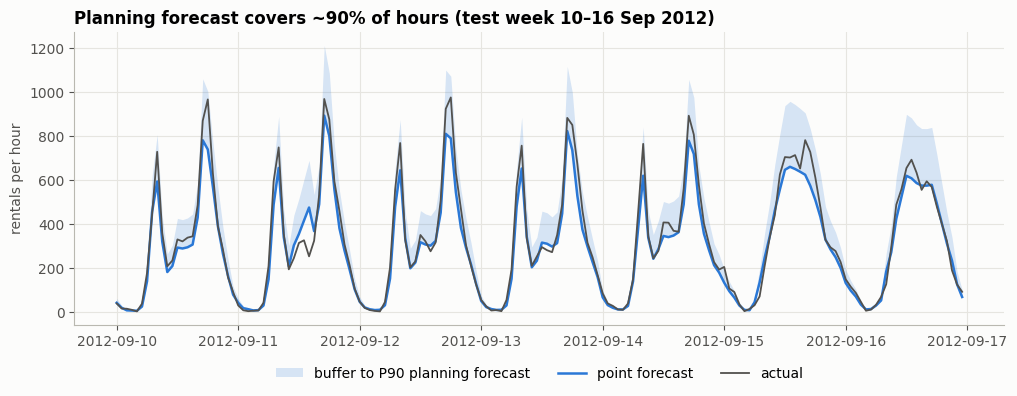

In [15]:
qm = {k: clone(v).fit(train[F], train.cnt) for k, v in mt.quantile_models().items()}
test["q10"], test["q90"] = qm["P10"].predict(test[F]), qm["P90"].predict(test[F])
cov_q90 = (test.cnt <= test.q90).mean()

oof = mt.out_of_fold_predictions(models[final_name], train, F)
mult = mt.planning_multipliers(train.loc[oof.index, "cnt"], oof, train.loc[oof.index, "rush_hour"], q=0.9)
test["plan90"] = mt.planning_forecast(test.pred, test.rush_hour, mult)
cov_plan = (test.cnt <= test.plan90).mean()

cov = pd.DataFrame({
    "all hours": [cov_q90, cov_plan],
    "working-day rush hours": [(test.cnt <= test.q90)[test.rush_hour == 1].mean(), (test.cnt <= test.plan90)[test.rush_hour == 1].mean()],
    "avg uplift vs point forecast": [(test.q90 - test.pred).mean(), (test.plan90 - test.pred).mean()],
}, index=["Quantile GB (P90)", "Calibrated multiplier (P90)"])
print("Calibrated multipliers (from validation folds):", {k: round(v, 3) for k, v in mult.items()})
display(cov.round(3))

fig, ax = plt.subplots(figsize=(12, 3.8))
wk = test[(test.dteday >= "2012-09-10") & (test.dteday <= "2012-09-16")]
ax.fill_between(wk.timestamp, wk.pred, wk.plan90, color=BLUE, alpha=.18, linewidth=0, label="buffer to P90 planning forecast")
ax.plot(wk.timestamp, wk.pred, color=BLUE, lw=1.8, label="point forecast")
ax.plot(wk.timestamp, wk.cnt, color=INK2, lw=1.3, label="actual")
ax.set(title="Planning forecast covers ~90% of hours (test week 10–16 Sep 2012)", ylabel="rentals per hour"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.show()


## 8. Bikes on the road (Little's law, assumed trip time)


,17:00 avg actual -> bikes on road,17:00 P90 plan -> bikes on road,busiest test day P90 -> bikes on road,13:00 avg actual -> bikes on road,03:00 avg actual -> bikes on road
"avg trip (min, ASSUMED)",,,,,
15,181.0,216.0,303.0,69.0,2.0
20,241.0,288.0,404.0,92.0,2.0
30,361.0,431.0,607.0,137.0,3.0


With a 20-min trip assumption: P90 bikes on the road peaks at 288 (hour 17:00) on an average working day.
Share of that peak requirement that is NOT on the road (avg actual) at 13:00: 68%, at 03:00: 99%
Busiest test day: P90 peak 1213 rentals/hr on 2012-09-11 -> 404 bikes on the road


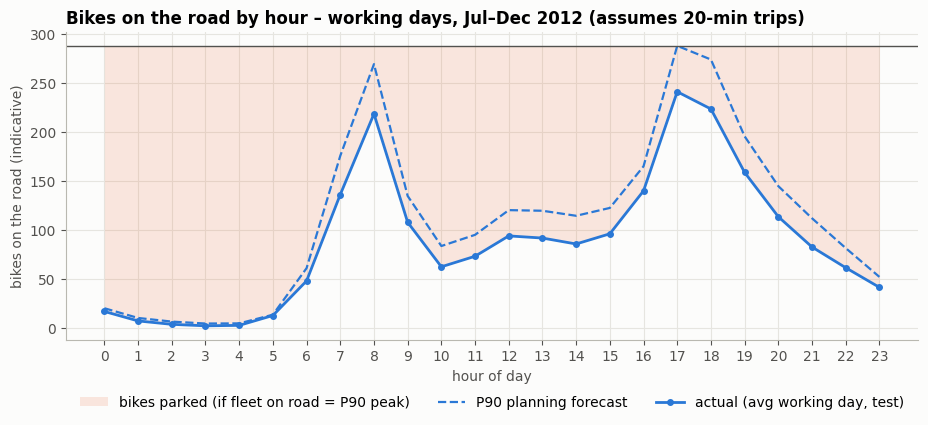

In [16]:
TRIP_MIN = [15, 20, 30]
wd = test[(test.workingday == 1) & (test.disrupted_day == 0)]
prof = wd.groupby("hr")[["cnt", "pred", "plan90"]].mean()
busiest = wd.groupby("dteday").plan90.max()

rows = []
for w in TRIP_MIN:
    rows.append({"avg trip (min, ASSUMED)": w,
                 "17:00 avg actual -> bikes on road": mt.bikes_in_use(prof.loc[17, "cnt"], w),
                 "17:00 P90 plan -> bikes on road": mt.bikes_in_use(prof.loc[17, "plan90"], w),
                 "busiest test day P90 -> bikes on road": mt.bikes_in_use(busiest.max(), w),
                 "13:00 avg actual -> bikes on road": mt.bikes_in_use(prof.loc[13, "cnt"], w),
                 "03:00 avg actual -> bikes on road": mt.bikes_in_use(prof.loc[3, "cnt"], w)})
little = pd.DataFrame(rows).set_index("avg trip (min, ASSUMED)")
display(little.round(0))

w = 20
inuse = mt.bikes_in_use(prof, w)
peak_need = inuse.plan90.max()
print(f"With a {w}-min trip assumption: P90 bikes on the road peaks at {peak_need:.0f} (hour {inuse.plan90.idxmax()}:00) on an average working day.")
print(f"Share of that peak requirement that is NOT on the road (avg actual) at 13:00: {1 - inuse.loc[13, 'cnt'] / peak_need:.0%}, at 03:00: {1 - inuse.loc[3, 'cnt'] / peak_need:.0%}")
print(f"Busiest test day: P90 peak {busiest.max():.0f} rentals/hr on {busiest.idxmax().date()} -> {mt.bikes_in_use(busiest.max(), w):.0f} bikes on the road")

fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(inuse.index, inuse.cnt, inuse.plan90.max(), color=ORANGE, alpha=.15, linewidth=0,
                label="bikes parked (if fleet on road = P90 peak)")
ax.plot(inuse.index, inuse.plan90, color=BLUE, ls="--", lw=1.6, label="P90 planning forecast")
ax.plot(inuse.index, inuse.cnt, color=BLUE, marker="o", markersize=4, label="actual (avg working day, test)")
ax.axhline(inuse.plan90.max(), color=INK2, lw=1)
ax.set(title=f"Bikes on the road by hour – working days, Jul–Dec 2012 (assumes {w}-min trips)", xlabel="hour of day",
       ylabel="bikes on the road (indicative)", xticks=range(24)); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
plt.show()


## 9. Save the model


In [17]:
deploy_model = clone(models[final_name]).fit(hour[F], hour.cnt)
climate = mt.climate_table(hour)

bundle_path = "models/best_model.joblib"
mt.save_bundle(bundle_path, model=deploy_model, features=F, model_name=final_name,
               planning_multipliers=mult, climate=climate, trained_on="2011-01-01..2012-12-31",
               test_metrics=test_table.loc[final_name].to_dict(), cv_metrics=cv_summary.loc[final_name].to_dict(),
               notes="Point forecast of hourly rentals; demand level of 2012 (yr capped at 1).")

b = mt.load_bundle(bundle_path)
chk = mt.scenario_frame("2012-09-12", hours=[8, 17], weather=1, climate=b["climate"])
print("Reloaded OK: predicted rentals at 08:00 and 17:00 =", np.round(b["model"].predict(chk[b["features"]])).tolist(), "| sklearn", b["sklearn_version"])
print("Saved:", bundle_path, f"({os.path.getsize(bundle_path) / 1e6:.1f} MB)")


Reloaded OK: predicted rentals at 08:00 and 17:00 = [748.0, 866.0] | sklearn 1.7.2
Saved: models/best_model.joblib (3.5 MB)
